<a href="https://colab.research.google.com/github/adinuansah/people-attrition-prediction/blob/main/notebooks/02_workforce_attrition_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Workforce Attrition — Exploratory Analysis

## Business Objective

Analyze historical voluntary employee turnover and
workforce composition using a fixed synthetic HRIS dataset.

The analysis will examine turnover trends, organizational
differences, and potential areas for further investigation.

## Methodology

- Validate employee, departure, and snapshot records.
- Calculate historical workforce turnover metrics.
- Investigate organizational and tenure patterns.
- Evaluate uncertainty and analytical limitations.

## Data Considerations

All employee records are synthetic.
Findings do not represent actual employee behavior.
The original source data will remain unchanged.

In [2]:

import pandas as pd
import numpy as np

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "adinuansah/people-attrition-prediction/"
    "main/data/synthetic/"
)

employees = pd.read_csv(
    BASE_URL + "employees.csv",
    parse_dates=["hire_date"]
)

exits = pd.read_csv(
    BASE_URL + "employment_exits.csv",
    parse_dates=["exit_date"]
)

snapshots = pd.read_csv(
    BASE_URL + "monthly_snapshots.csv",
    parse_dates=["snapshot_date", "hire_date"]
)

print("Employee records:", len(employees))
print("Departure records:", len(exits))
print("Monthly snapshot records:", len(snapshots))

print("\nSnapshot date range:")
print(
    snapshots["snapshot_date"].min(),
    "to",
    snapshots["snapshot_date"].max()
)

print("\nDeparture types:")
print(exits["exit_type"].value_counts())


Employee records: 2000
Departure records: 570
Monthly snapshot records: 59065

Snapshot date range:
2022-01-31 00:00:00 to 2025-12-31 00:00:00

Departure types:
exit_type
Voluntary      442
Involuntary    128
Name: count, dtype: int64


## Data Quality Assessment

### Primary Key and Record Uniqueness

Validate record-level uniqueness across employee master
data, departure events, and monthly workforce snapshots.

The synthetic dataset assumes one employment spell per
employee and a maximum of one recorded departure.

In [3]:

# Lesson 4.2 — Primary Key Uniqueness Audit

employee_duplicates = employees.duplicated(
    subset=["employee_id"]
).sum()

exit_duplicates = exits.duplicated(
    subset=["employee_id"]
).sum()

snapshot_duplicates = snapshots.duplicated(
    subset=["employee_id", "snapshot_date"]
).sum()

print("DATA UNIQUENESS AUDIT")
print("-" * 40)

print(
    "Duplicate employee IDs:",
    employee_duplicates
)

print(
    "Duplicate exit employee IDs:",
    exit_duplicates
)

print(
    "Duplicate employee-month records:",
    snapshot_duplicates
)

# Assertions verify the expected data structure

assert employee_duplicates == 0
assert exit_duplicates == 0
assert snapshot_duplicates == 0

print("\nPASS: All uniqueness checks passed.")


DATA UNIQUENESS AUDIT
----------------------------------------
Duplicate employee IDs: 0
Duplicate exit employee IDs: 0
Duplicate employee-month records: 0

PASS: All uniqueness checks passed.


### Referential Integrity

Verify that employee identifiers in the departure and
monthly snapshot tables correspond to records in the
employee master dataset.

Unmatched records would require investigation before
using the data for workforce metrics.

In [4]:

# Lesson 4.3 — Referential Integrity Audit

# All valid employee IDs
employee_ids = set(
    employees["employee_id"]
)

# IDs referenced by departure records
exit_ids = set(
    exits["employee_id"]
)

# IDs referenced by monthly snapshots
snapshot_ids = set(
    snapshots["employee_id"]
)

# Find IDs that do not exist in employee master data
orphan_exit_ids = exit_ids - employee_ids

orphan_snapshot_ids = snapshot_ids - employee_ids

print("REFERENTIAL INTEGRITY AUDIT")
print("-" * 40)

print(
    "Exit records referencing unknown employees:",
    len(orphan_exit_ids)
)

print(
    "Snapshot records referencing unknown employees:",
    len(orphan_snapshot_ids)
)

# Verify that every referenced employee is known
assert len(orphan_exit_ids) == 0
assert len(orphan_snapshot_ids) == 0

print("\nPASS: Employee references are valid.")


REFERENTIAL INTEGRITY AUDIT
----------------------------------------
Exit records referencing unknown employees: 0
Snapshot records referencing unknown employees: 0

PASS: Employee references are valid.


### Employment-Date Consistency

Validate that recorded employee departures occur after
their corresponding hire dates.

Departure records are joined to employee master data
using the employee identifier.

Invalid employment sequences are flagged for review
before historical turnover metrics are calculated.

In [5]:

# Lesson 4.4 — Employment Date Audit

# Join departure events with employee hire dates
exit_audit = exits.merge(
    employees[["employee_id", "hire_date"]],
    on="employee_id",
    how="left",
    validate="one_to_one"
)

# Check whether any dates are missing
missing_hire_dates = (
    exit_audit["hire_date"].isna().sum()
)

missing_exit_dates = (
    exit_audit["exit_date"].isna().sum()
)

# An exit must occur strictly after hiring
invalid_exit_dates = (
    exit_audit["exit_date"]
    <= exit_audit["hire_date"]
).sum()

print("EMPLOYMENT-DATE AUDIT")
print("-" * 40)

print("Departure records:", len(exit_audit))
print("Missing hire dates:", missing_hire_dates)
print("Missing exit dates:", missing_exit_dates)
print(
    "Exits on or before hire date:",
    invalid_exit_dates
)

assert len(exit_audit) == len(exits)
assert missing_hire_dates == 0
assert missing_exit_dates == 0
assert invalid_exit_dates == 0

print("\nPASS: Departure dates are chronologically valid.")


EMPLOYMENT-DATE AUDIT
----------------------------------------
Departure records: 570
Missing hire dates: 0
Missing exit dates: 0
Exits on or before hire date: 0

PASS: Departure dates are chronologically valid.


### Snapshot Employment-Period Validation

Verify that month-end workforce snapshots occur on or
after each employee's hire date and strictly before
any recorded exit date.

The audit reconciles snapshot records with employee
master data and departure events to identify invalid
active-workforce observations.

In [6]:

# Lesson 4.5 — Snapshot Employment-Period Audit

# Attach employee master hire dates
snapshot_audit = snapshots.merge(
    employees[["employee_id", "hire_date"]],
    on="employee_id",
    how="left",
    validate="many_to_one",
    suffixes=("_snapshot", "_master")
)

# Attach departure dates
snapshot_audit = snapshot_audit.merge(
    exits[["employee_id", "exit_date"]],
    on="employee_id",
    how="left",
    validate="many_to_one"
)

# Check for missing master hire dates
missing_master_hires = (
    snapshot_audit["hire_date_master"].isna().sum()
)

# Check snapshots before hire
snapshots_before_hire = (
    snapshot_audit["snapshot_date"]
    < snapshot_audit["hire_date_master"]
).sum()

# Check snapshots on or after a recorded exit
snapshots_after_exit = (
    (
        snapshot_audit["exit_date"].notna()
    )
    &
    (
        snapshot_audit["snapshot_date"]
        >= snapshot_audit["exit_date"]
    )
).sum()

print("SNAPSHOT EMPLOYMENT-PERIOD AUDIT")
print("-" * 40)

print("Snapshot records:", len(snapshot_audit))
print("Missing master hire dates:", missing_master_hires)
print("Snapshots before hire:", snapshots_before_hire)
print(
    "Snapshots on or after exit:",
    snapshots_after_exit
)

# Ensure joins didn't duplicate records
assert len(snapshot_audit) == len(snapshots)

# Validate employment chronology
assert missing_master_hires == 0
assert snapshots_before_hire == 0
assert snapshots_after_exit == 0

print("\nPASS: Snapshot employment periods are valid.")


SNAPSHOT EMPLOYMENT-PERIOD AUDIT
----------------------------------------
Snapshot records: 59065
Missing master hire dates: 0
Snapshots before hire: 0
Snapshots on or after exit: 0

PASS: Snapshot employment periods are valid.


### Month-End Workforce Completeness

Reconstruct expected month-end active headcount from
employee hire dates and recorded departure dates.

Compare expected headcount with the observed monthly
snapshot table to identify missing or excess workforce
records.

Employees are active at month-end if hired on or before
that date and not departed by that date.

In [7]:

# Lesson 4.6 — Expected vs. Actual Headcount

# Attach departure dates to employee master records
employment_history = employees.merge(
    exits[["employee_id", "exit_date"]],
    on="employee_id",
    how="left",
    validate="one_to_one"
)

# All month-end dates in our snapshot history
month_ends = pd.date_range(
    start=snapshots["snapshot_date"].min(),
    end=snapshots["snapshot_date"].max(),
    freq="ME"
)

headcount_records = []

for month_end in month_ends:

    # Employees active at this month-end
    active = (
        (employment_history["hire_date"] <= month_end)
        &
        (
            employment_history["exit_date"].isna()
            |
            (employment_history["exit_date"] > month_end)
        )
    )

    expected_headcount = int(active.sum())

    actual_headcount = int(
        (snapshots["snapshot_date"] == month_end).sum()
    )

    headcount_records.append({
        "snapshot_date": month_end,
        "expected_headcount": expected_headcount,
        "actual_headcount": actual_headcount
    })

headcount_audit = pd.DataFrame(headcount_records)

headcount_audit["difference"] = (
    headcount_audit["actual_headcount"]
    - headcount_audit["expected_headcount"]
)

display(headcount_audit.head())

print(
    "\nMonths checked:",
    len(headcount_audit)
)

print(
    "Months with mismatched headcount:",
    (headcount_audit["difference"] != 0).sum()
)

print(
    "Total expected snapshots:",
    headcount_audit["expected_headcount"].sum()
)

print(
    "Total actual snapshots:",
    headcount_audit["actual_headcount"].sum()
)


,snapshot_date,expected_headcount,actual_headcount,difference
0,2022-01-31,901,901,0
1,2022-02-28,925,925,0
2,2022-03-31,940,940,0
3,2022-04-30,955,955,0
4,2022-05-31,977,977,0



Months checked: 48
Months with mismatched headcount: 0
Total expected snapshots: 59065
Total actual snapshots: 59065



### Employee-Month Completeness Validation

Reconstruct the expected employee-month population from
employment histories and reporting month-end dates.

Compare the expected employee-month keys against the
observed workforce snapshot keys.

The audit identifies missing or unexpected records that
could remain undetected in aggregate headcount checks.


In [8]:

# Lesson 4.7 — Employee-Month Completeness Audit

# Build expected employee-month records
expected_records = []

for month_end in month_ends:

    active = employment_history.loc[
        (employment_history["hire_date"] <= month_end)
        &
        (
            employment_history["exit_date"].isna()
            |
            (employment_history["exit_date"] > month_end)
        ),
        ["employee_id"]
    ].copy()

    active["snapshot_date"] = month_end

    expected_records.append(active)

expected_snapshots = pd.concat(
    expected_records,
    ignore_index=True
)

# Compare expected and observed employee-month keys
observed_keys = snapshots[
    ["employee_id", "snapshot_date"]
].copy()

expected_keys = expected_snapshots[
    ["employee_id", "snapshot_date"]
].copy()

coverage_audit = expected_keys.merge(
    observed_keys,
    on=["employee_id", "snapshot_date"],
    how="outer",
    indicator=True,
    validate="one_to_one"
)

print("EMPLOYEE-MONTH COMPLETENESS AUDIT")
print("-" * 40)

print("Expected records:", len(expected_keys))
print("Observed records:", len(observed_keys))

print("\nReconciliation:")
print(coverage_audit["_merge"].value_counts())

print("\nMissing expected records:",
      (coverage_audit["_merge"] == "left_only").sum())

print("Unexpected observed records:",
      (coverage_audit["_merge"] == "right_only").sum())


EMPLOYEE-MONTH COMPLETENESS AUDIT
----------------------------------------
Expected records: 59065
Observed records: 59065

Reconciliation:
_merge
both          59065
left_only         0
right_only        0
Name: count, dtype: int64

Missing expected records: 0
Unexpected observed records: 0



## Historical Voluntary Turnover

### Monthly Voluntary Departure Counts

Aggregate recorded voluntary departures by calendar month.

Departure events provide the numerator for monthly
voluntary turnover calculations.

The turnover denominator will be constructed separately
using validated workforce headcount.


In [9]:

# Lesson 4.8 — Step 1
# Count voluntary departures by calendar month

voluntary_exits = exits.loc[
    exits["exit_type"] == "Voluntary"
].copy()

# Assign each departure to its calendar month-end
voluntary_exits["month_end"] = (
    voluntary_exits["exit_date"]
    + pd.offsets.MonthEnd(0)
)

# Count recorded voluntary departures per month
monthly_voluntary_exits = (
    voluntary_exits.groupby("month_end")
    .size()
    .rename("voluntary_exits")
    .reset_index()
)

# Include months with zero voluntary departures
monthly_voluntary_exits = (
    pd.DataFrame({"month_end": month_ends})
    .merge(
        monthly_voluntary_exits,
        on="month_end",
        how="left",
        validate="one_to_one"
    )
)

monthly_voluntary_exits["voluntary_exits"] = (
    monthly_voluntary_exits["voluntary_exits"]
    .fillna(0)
    .astype(int)
)

display(monthly_voluntary_exits.head(10))

print(
    "\nMonths:",
    len(monthly_voluntary_exits)
)

print(
    "Voluntary departures in reporting period:",
    monthly_voluntary_exits["voluntary_exits"].sum()
)

print(
    "Total voluntary departures in source:",
    len(voluntary_exits)
)


,month_end,voluntary_exits
0,2022-01-31,8
1,2022-02-28,1
2,2022-03-31,10
3,2022-04-30,4
4,2022-05-31,5
5,2022-06-30,10
6,2022-07-31,9
7,2022-08-31,5
8,2022-09-30,7
9,2022-10-31,5



Months: 48
Voluntary departures in reporting period: 442
Total voluntary departures in source: 442



### Beginning-of-Period Headcount

Reconstruct active headcount at December 31, 2021,
the opening boundary for January 2022 reporting.

The calculation uses employee hire dates and recorded
departure dates because no December 2021 snapshot is
available.

This reconstructed value will be used as January's
beginning headcount.


In [10]:

# Lesson 4.9 — Step 1
# Reconstruct January 2022 opening headcount

OPENING_DATE = pd.Timestamp("2021-12-31")

opening_active = (
    (employment_history["hire_date"] <= OPENING_DATE)
    &
    (
        employment_history["exit_date"].isna()
        |
        (employment_history["exit_date"] > OPENING_DATE)
    )
)

opening_headcount = int(opening_active.sum())

# Compare with the first observed month-end
january_ending_headcount = int(
    (
        snapshots["snapshot_date"]
        == pd.Timestamp("2022-01-31")
    ).sum()
)

print("Opening headcount:", opening_headcount)
print(
    "January ending headcount:",
    january_ending_headcount
)

print(
    "January net headcount change:",
    january_ending_headcount - opening_headcount
)


Opening headcount: 877
January ending headcount: 901
January net headcount change: 24



### January 2022 Workforce Movement Reconciliation

Reconcile beginning and ending workforce headcount
against employee hire and departure events.

All recorded exit types are included in the headcount
reconciliation because both voluntary and involuntary
departures reduce active workforce size.

The calculation uses the synthetic employment history
and the established month-end employment-status rules.


In [11]:

# Lesson 4.10 — January Workforce Movements

JAN_START = pd.Timestamp("2022-01-01")
JAN_END = pd.Timestamp("2022-01-31")

# Count employees hired during January
january_hires = employees[
    employees["hire_date"].between(
        JAN_START, JAN_END
    )
].shape[0]

# Count all departures during January
january_exits = exits[
    exits["exit_date"].between(
        JAN_START, JAN_END
    )
].shape[0]

# Reconstruct ending headcount
reconciled_headcount = (
    opening_headcount
    + january_hires
    - january_exits
)

print("JANUARY 2022 WORKFORCE RECONCILIATION")
print("-" * 45)

print("Opening headcount:", opening_headcount)
print("January hires:", january_hires)
print("January exits:", january_exits)
print("Net movement:", january_hires - january_exits)

print("\nReconstructed ending headcount:",
      reconciled_headcount)

print("Observed ending headcount:",
      january_ending_headcount)

print("Reconciliation difference:",
      reconciled_headcount - january_ending_headcount)


JANUARY 2022 WORKFORCE RECONCILIATION
---------------------------------------------
Opening headcount: 877
January hires: 33
January exits: 9
Net movement: 24

Reconstructed ending headcount: 901
Observed ending headcount: 901
Reconciliation difference: 0


### Monthly Average Workforce Headcount

Construct beginning, ending, and average monthly
headcount using validated active workforce snapshots.

For January 2022, the opening headcount is reconstructed
from employee hire and departure histories.

For subsequent months, beginning headcount is defined
as the previous month's ending headcount.

Average headcount is calculated as the arithmetic mean
of beginning and ending workforce counts.

In [12]:

# Lesson 4.11 — Monthly Average Headcount

# Calculate ending headcount from snapshots
monthly_headcount = (
    snapshots.groupby("snapshot_date")
    .size()
    .rename("ending_headcount")
    .reset_index()
    .sort_values("snapshot_date")
    .reset_index(drop=True)
)

# Beginning headcount is the previous month's ending HC
monthly_headcount["beginning_headcount"] = (
    monthly_headcount["ending_headcount"].shift(1)
)

# January 2022 uses the reconstructed opening HC
monthly_headcount.loc[
    0, "beginning_headcount"
] = opening_headcount

monthly_headcount["beginning_headcount"] = (
    monthly_headcount["beginning_headcount"].astype(int)
)

# Calculate average monthly headcount
monthly_headcount["average_headcount"] = (
    monthly_headcount["beginning_headcount"]
    + monthly_headcount["ending_headcount"]
) / 2

display(monthly_headcount.head(6))

print("Months calculated:", len(monthly_headcount))

print(
    "January average headcount:",
    monthly_headcount.loc[0, "average_headcount"]
)


,snapshot_date,ending_headcount,beginning_headcount,average_headcount
0,2022-01-31,901,877,889.0
1,2022-02-28,925,901,913.0
2,2022-03-31,940,925,932.5
3,2022-04-30,955,940,947.5
4,2022-05-31,977,955,966.0
5,2022-06-30,992,977,984.5


Months calculated: 48
January average headcount: 889.0


In [13]:

# Lesson 4.11 — Headcount Denominator Validation

# Confirm the full reporting period
assert len(monthly_headcount) == 48

# Confirm January's opening and ending HC
assert monthly_headcount.loc[
    0, "beginning_headcount"
] == 877

assert monthly_headcount.loc[
    0, "ending_headcount"
] == 901

# Each subsequent opening HC should equal
# the previous month's closing HC
assert (
    monthly_headcount["beginning_headcount"]
    .iloc[1:].to_numpy()
    ==
    monthly_headcount["ending_headcount"]
    .iloc[:-1].to_numpy()
).all()

# Every denominator must be positive
assert (
    monthly_headcount["average_headcount"] > 0
).all()

# Reconcile January's average
assert (
    monthly_headcount.loc[0, "average_headcount"]
    == 889
)

print("PASS: Monthly headcount denominators validated.")

print(
    "Minimum monthly average headcount:",
    monthly_headcount["average_headcount"].min()
)

print(
    "Maximum monthly average headcount:",
    monthly_headcount["average_headcount"].max()
)


PASS: Monthly headcount denominators validated.
Minimum monthly average headcount: 889.0
Maximum monthly average headcount: 1471.5



## Monthly Voluntary Turnover Rates

Calculate monthly voluntary employee turnover using
recorded voluntary departure events and average active
workforce headcount.

Average headcount is defined as the arithmetic mean of
beginning-of-month and ending-of-month headcount.

The January 2022 opening headcount is reconstructed
from employment histories.

All workforce data is synthetic.


In [14]:

# Lesson 4.12 — Monthly Voluntary Turnover

# Align the headcount and departure tables
monthly_turnover = monthly_headcount.rename(
    columns={"snapshot_date": "month_end"}
).merge(
    monthly_voluntary_exits,
    on="month_end",
    how="left",
    validate="one_to_one"
)

# Confirm every reporting month has an exit count
assert monthly_turnover["voluntary_exits"].notna().all()

# Calculate monthly voluntary turnover rate
monthly_turnover["voluntary_turnover_pct"] = (
    monthly_turnover["voluntary_exits"]
    / monthly_turnover["average_headcount"]
    * 100
)

# Display the first 12 months
display(
    monthly_turnover[
        [
            "month_end",
            "beginning_headcount",
            "ending_headcount",
            "average_headcount",
            "voluntary_exits",
            "voluntary_turnover_pct"
        ]
    ].head(12).round(3)
)


,month_end,beginning_headcount,ending_headcount,average_headcount,voluntary_exits,voluntary_turnover_pct
0,2022-01-31,877,901,889.0,8,0.900
1,2022-02-28,901,925,913.0,1,0.110
2,2022-03-31,925,940,932.5,10,1.072
3,2022-04-30,940,955,947.5,4,0.422
4,2022-05-31,955,977,966.0,5,0.518
5,2022-06-30,977,992,984.5,10,1.016
6,2022-07-31,992,1008,1000.0,9,0.900
7,2022-08-31,1008,1035,1021.5,5,0.489
8,2022-09-30,1035,1052,1043.5,7,0.671
9,2022-10-31,1052,1065,1058.5,5,0.472


In [15]:

# Lesson 4.12 — Monthly Turnover Validation

# Check reporting period coverage
assert len(monthly_turnover) == 48

assert monthly_turnover["month_end"].is_unique

# Check event-count reconciliation
assert (
    monthly_turnover["voluntary_exits"].sum()
    == 442
)

# Validate denominators
assert (
    monthly_turnover["average_headcount"] > 0
).all()

# Validate calculated rates
assert (
    monthly_turnover["voluntary_turnover_pct"]
    .notna().all()
)

assert (
    monthly_turnover["voluntary_turnover_pct"]
    >= 0
).all()

# Verify calculation using the original columns
expected_rates = (
    monthly_turnover["voluntary_exits"]
    / monthly_turnover["average_headcount"]
    * 100
)

assert np.allclose(
    monthly_turnover["voluntary_turnover_pct"],
    expected_rates
)

print("PASS: Monthly turnover calculations validated.")

print(
    "\nReporting months:",
    len(monthly_turnover)
)

print(
    "Total voluntary departures:",
    monthly_turnover["voluntary_exits"].sum()
)

print(
    "Minimum monthly turnover:",
    round(
        monthly_turnover["voluntary_turnover_pct"].min(),
        3
    ),
    "%"
)

print(
    "Maximum monthly turnover:",
    round(
        monthly_turnover["voluntary_turnover_pct"].max(),
        3
    ),
    "%"
)


PASS: Monthly turnover calculations validated.

Reporting months: 48
Total voluntary departures: 442
Minimum monthly turnover: 0.11 %
Maximum monthly turnover: 1.251 %



## Historical Turnover Trends

### Monthly Voluntary Turnover

Visualize monthly voluntary turnover rates across the
2022–2025 reporting period.

The chart supports an initial assessment of temporal
variation and potential longer-term patterns.

Rates are based on observed voluntary departures
divided by average monthly workforce headcount.


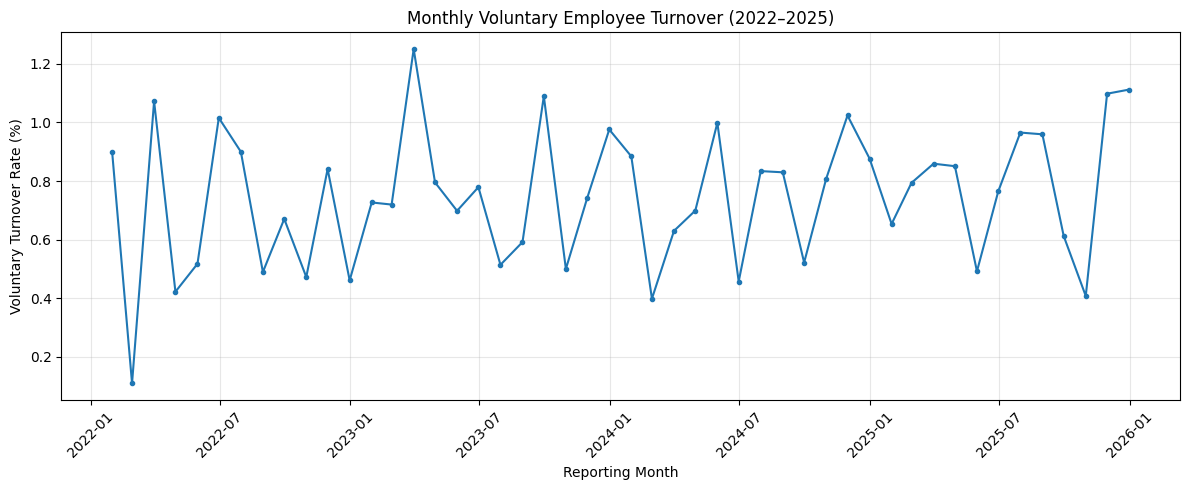

In [16]:

# Lesson 4.13 — Monthly Turnover Trend

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_turnover["month_end"],
    monthly_turnover["voluntary_turnover_pct"],
    marker="o",
    markersize=3,
    linewidth=1.5
)

ax.set_title(
    "Monthly Voluntary Employee Turnover (2022–2025)"
)

ax.set_xlabel("Reporting Month")
ax.set_ylabel("Voluntary Turnover Rate (%)")

ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


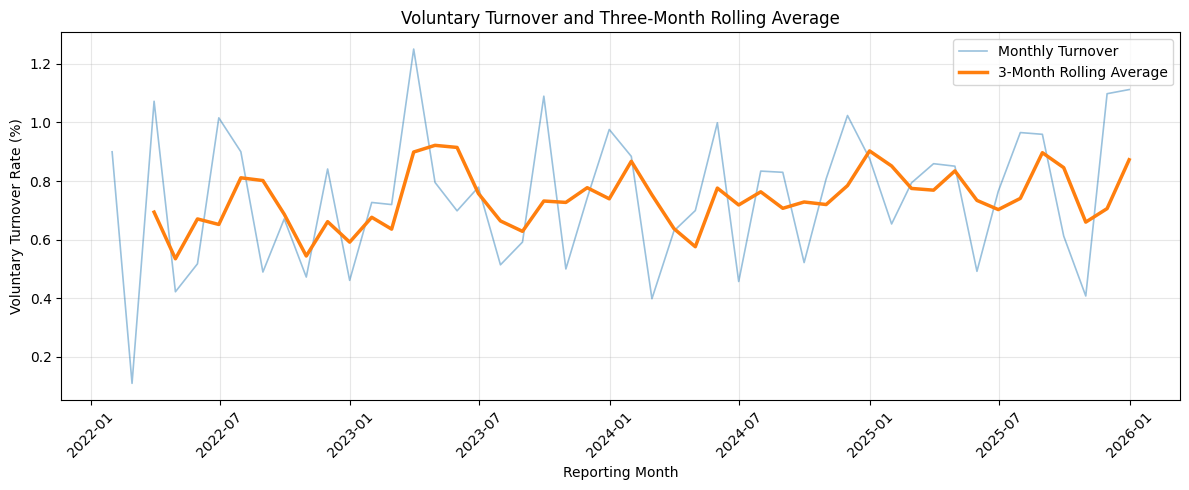

In [17]:

# Lesson 4.13 — Three-Month Rolling Average

monthly_turnover["turnover_3m_rolling_avg"] = (
    monthly_turnover["voluntary_turnover_pct"]
    .rolling(window=3, min_periods=3)
    .mean()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_turnover["month_end"],
    monthly_turnover["voluntary_turnover_pct"],
    alpha=0.45,
    linewidth=1.2,
    label="Monthly Turnover"
)

ax.plot(
    monthly_turnover["month_end"],
    monthly_turnover["turnover_3m_rolling_avg"],
    linewidth=2.5,
    label="3-Month Rolling Average"
)

ax.set_title(
    "Voluntary Turnover and Three-Month Rolling Average"
)

ax.set_xlabel("Reporting Month")
ax.set_ylabel("Voluntary Turnover Rate (%)")

ax.legend()
ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## Annual Voluntary Turnover

Aggregate monthly voluntary departure counts and
average workforce headcount by reporting year.

Annual turnover is defined as total voluntary
departures during the year divided by the arithmetic
mean of monthly average headcount.

This calculation follows a consistent reporting
convention across 2022–2025.

Results describe synthetic workforce activity and
do not establish causal relationships.


In [18]:

# Lesson 4.14 — Annual Voluntary Turnover Summary

# Work from the validated monthly turnover table
annual_data = monthly_turnover.copy()

# Extract calendar year
annual_data["year"] = (
    annual_data["month_end"].dt.year
)

# Aggregate events and workforce denominator
annual_turnover = (
    annual_data.groupby("year")
    .agg(
        reporting_months=("month_end", "count"),
        voluntary_exits=("voluntary_exits", "sum"),
        average_annual_headcount=(
            "average_headcount", "mean"
        )
    )
    .reset_index()
)

# Calculate annual turnover rate
annual_turnover["annual_turnover_pct"] = (
    annual_turnover["voluntary_exits"]
    / annual_turnover["average_annual_headcount"]
    * 100
)

display(annual_turnover.round(3))


,year,reporting_months,voluntary_exits,average_annual_headcount,annual_turnover_pct
0,2022,12,78,992.542,7.859
1,2023,12,109,1162.375,9.377
2,2024,12,118,1312.792,8.988
3,2025,12,137,1431.333,9.571


In [19]:

# Lesson 4.14 — Annual Turnover Validation

# Exactly four reporting years
assert annual_turnover["year"].tolist() == [
    2022, 2023, 2024, 2025
]

# Each year must contain 12 reporting months
assert (
    annual_turnover["reporting_months"] == 12
).all()

# Annual exit counts must reconcile to source total
assert (
    annual_turnover["voluntary_exits"].sum()
    == 442
)

# Denominators must be valid
assert (
    annual_turnover["average_annual_headcount"] > 0
).all()

# Rates must be finite and nonnegative
assert np.isfinite(
    annual_turnover["annual_turnover_pct"]
).all()

assert (
    annual_turnover["annual_turnover_pct"] >= 0
).all()

print("PASS: Annual turnover summary validated.")

print(
    "\nTotal annual departures:",
    annual_turnover["voluntary_exits"].sum()
)


PASS: Annual turnover summary validated.

Total annual departures: 442



## Statistical Assessment of Annual Turnover

Compare voluntary turnover in 2022 and 2025 using
an approximate event-rate ratio and confidence interval.

Average annual workforce headcount is used as an
approximation of workforce exposure.

This analysis is descriptive and exploratory.
The synthetic population and statistical assumptions
limit generalization to real organizations.


In [20]:

# Lesson 4.15 — Approximate Turnover Rate Ratio

from scipy.stats import norm
import numpy as np

year_2022 = annual_turnover.loc[
    annual_turnover["year"] == 2022
].iloc[0]

year_2025 = annual_turnover.loc[
    annual_turnover["year"] == 2025
].iloc[0]

# Annual exits
exits_2022 = year_2022["voluntary_exits"]
exits_2025 = year_2025["voluntary_exits"]

# Approximate exposure in employee-years
exposure_2022 = year_2022["average_annual_headcount"]
exposure_2025 = year_2025["average_annual_headcount"]

# Compare event rates
rate_ratio = (
    (exits_2025 / exposure_2025)
    /
    (exits_2022 / exposure_2022)
)

# Approximate standard error of log rate ratio
se_log_rr = np.sqrt(
    1 / exits_2025 + 1 / exits_2022
)

z = norm.ppf(0.975)

ci_lower = np.exp(
    np.log(rate_ratio) - z * se_log_rr
)

ci_upper = np.exp(
    np.log(rate_ratio) + z * se_log_rr
)

print("2025 vs. 2022 rate ratio:", round(rate_ratio, 3))
print(
    "Approximate 95% CI:",
    (round(ci_lower, 3), round(ci_upper, 3))
)


2025 vs. 2022 rate ratio: 1.218
Approximate 95% CI: (np.float64(0.922), np.float64(1.608))



## Summary of Findings and Limitations

### Workforce Trends

The synthetic workforce increased in average headcount
from approximately 993 employees in 2022 to 1,431
employees in 2025.

Recorded annual voluntary departures increased from
78 to 137 over the same period.

Annual voluntary turnover rates were:

| Year | Voluntary Turnover |
|---|---|
| 2022 | 7.86% |
| 2023 | 9.38% |
| 2024 | 8.99% |
| 2025 | 9.57% |

### Statistical Assessment

The estimated voluntary turnover rate ratio comparing
2025 with 2022 was 1.218, with an approximate 95%
confidence interval of 0.922–1.608.

The interval includes 1.0; therefore, the comparison
does not provide strong evidence of a difference in
underlying departure rates under the stated assumptions.

### Business Implications

Growth in departure counts should be interpreted
alongside changes in workforce size.

Observed turnover fluctuations warrant descriptive
monitoring, but these results alone do not establish
a sustained increase in underlying attrition risk.

### Limitations

- All data is synthetic.
- Annual turnover denominators use averaged monthly
  headcount rather than exact employee-time exposure.
- The rate-ratio interval relies on an approximate
  Poisson event model.
- Results do not establish causal relationships.
- No findings should be interpreted as evidence about
  real organizations or employees.
